CODEALPHA - DISEASE PREDICTION PROJECT

Dataset loaded successfully!
Dataset shape: (569, 30)
Number of features: 30
Number of records: 569

Target classes:
0 = malignant
1 = benign

First five records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414     

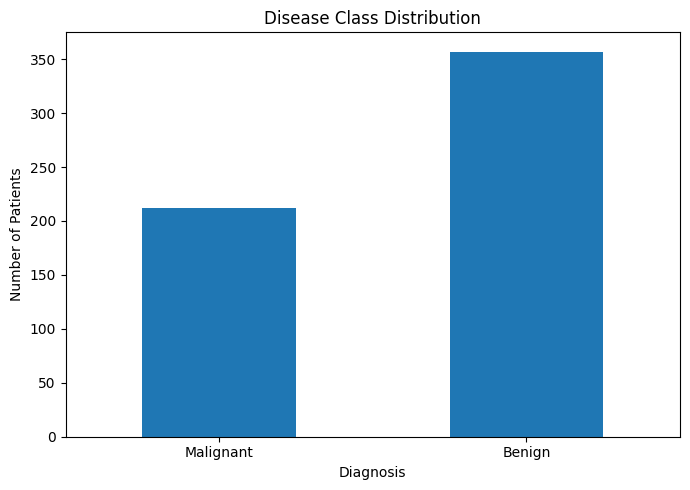


Training samples: 455
Testing samples: 114

Training: Logistic Regression
Accuracy: 98.25 %
Precision: 0.9861
Recall: 0.9861
F1 Score: 0.9861
ROC-AUC: 0.9954

Training: Random Forest
Accuracy: 95.61 %
Precision: 0.9589
Recall: 0.9722
F1 Score: 0.9655
ROC-AUC: 0.9931

Training: Support Vector Machine
Accuracy: 98.25 %
Precision: 0.9861
Recall: 0.9861
F1 Score: 0.9861
ROC-AUC: 0.995

MODEL PERFORMANCE COMPARISON
                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
   Logistic Regression    0.9825     0.9861  0.9861    0.9861   0.9954
         Random Forest    0.9561     0.9589  0.9722    0.9655   0.9931
Support Vector Machine    0.9825     0.9861  0.9861    0.9861   0.9950

Best model based on F1 Score: Logistic Regression

FINAL CLASSIFICATION REPORT
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   

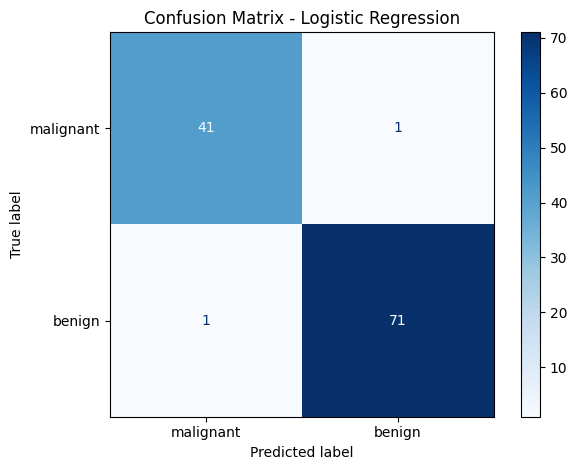

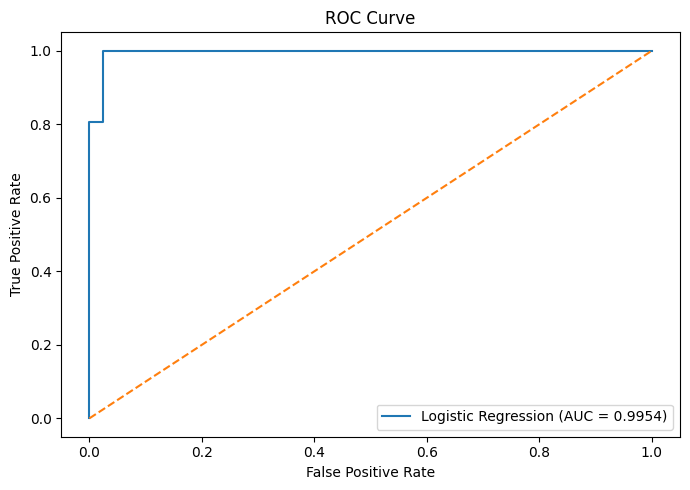

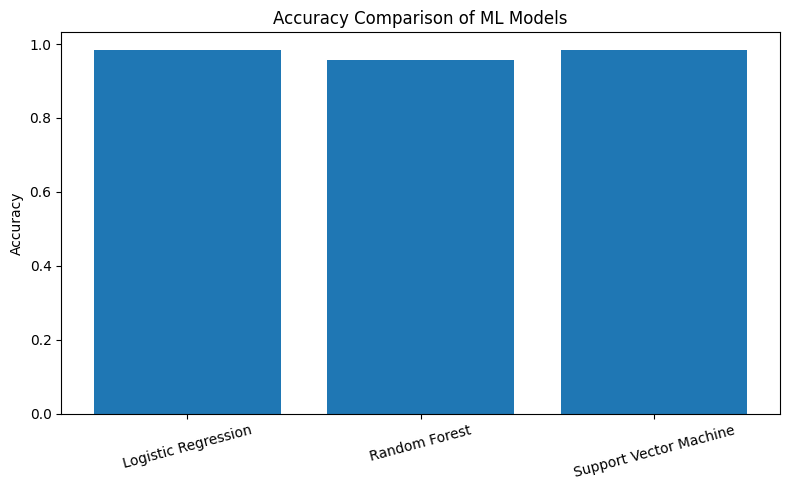

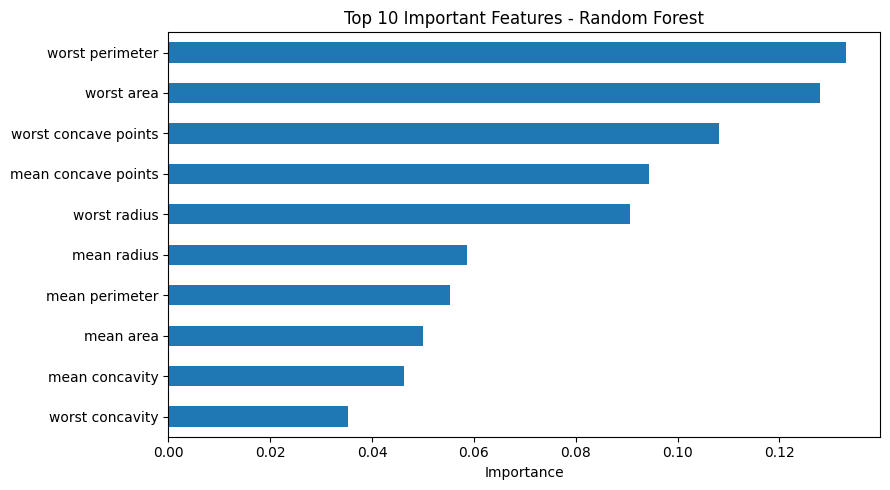


Top 10 important features:
worst perimeter         0.133100
worst area              0.128052
worst concave points    0.108107
mean concave points     0.094414
worst radius            0.090639
mean radius             0.058662
mean perimeter          0.055242
mean area               0.049938
mean concavity          0.046207
worst concavity         0.035357
dtype: float64

SAMPLE DISEASE PREDICTION
Predicted Class: malignant
Probability of Malignant: 100.0 %
Probability of Benign: 0.0 %

PROJECT EXECUTION COMPLETED SUCCESSFULLY!
Best Model: Logistic Regression
Project ZIP: CodeAlpha_DiseasePrediction_Project.zip
All project files saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# CODEALPHA MACHINE LEARNING INTERNSHIP
# PROJECT 2: DISEASE PREDICTION USING MACHINE LEARNING
# Dataset: Breast Cancer Wisconsin
# ============================================================

import os
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_curve
)

print("=" * 65)
print("CODEALPHA - DISEASE PREDICTION PROJECT")
print("=" * 65)

# 1. LOAD DATASET
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="diagnosis")

print("\nDataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Number of features:", X.shape[1])
print("Number of records:", len(X))

print("\nTarget classes:")
print("0 =", data.target_names[0])
print("1 =", data.target_names[1])

# 2. DATA EXPLORATION
print("\nFirst five records:")
print(X.head())

print("\nMissing values:", X.isnull().sum().sum())

print("\nClass distribution:")
print(y.value_counts().rename(index={
    0: "Malignant",
    1: "Benign"
}))

# 3. DATA VISUALIZATION
plt.figure(figsize=(7, 5))
y.value_counts().sort_index().plot(kind="bar")
plt.xticks([0, 1], ["Malignant", "Benign"], rotation=0)
plt.title("Disease Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Patients")
plt.tight_layout()
plt.show()

# 4. TRAIN TEST SPLIT
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# 5. BUILD MACHINE LEARNING MODELS
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(probability=True, random_state=42))
    ])
}

# 6. TRAIN AND EVALUATE MODELS
results = []
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions)
    recall = recall_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)
    auc = roc_auc_score(y_test, probabilities)

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": auc
    })

    trained_models[name] = model

    print("Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1 Score:", round(f1, 4))
    print("ROC-AUC:", round(auc, 4))

# 7. MODEL COMPARISON
results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("MODEL PERFORMANCE COMPARISON")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

best_name = results_df.sort_values(
    by="F1 Score", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]

print("\nBest model based on F1 Score:", best_name)

# 8. FINAL CLASSIFICATION REPORT
final_predictions = best_model.predict(X_test)
final_probabilities = best_model.predict_proba(X_test)[:, 1]

print("\nFINAL CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    final_predictions,
    target_names=data.target_names
))

# 9. CONFUSION MATRIX
cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - " + best_name)
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

# 10. ROC CURVE
fpr, tpr, thresholds = roc_curve(
    y_test, final_probabilities
)

auc_value = roc_auc_score(y_test, final_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{best_name} (AUC = {auc_value:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve.png")
plt.show()

# 11. MODEL ACCURACY COMPARISON GRAPH
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Accuracy"])
plt.title("Accuracy Comparison of ML Models")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("accuracy_comparison.png")
plt.show()

# 12. FEATURE IMPORTANCE (RANDOM FOREST)
rf_model = trained_models["Random Forest"]

importance = pd.Series(
    rf_model.feature_importances_,
    index=data.feature_names
).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png")
plt.show()

print("\nTop 10 important features:")
print(importance)

# 13. SAMPLE PREDICTION
sample = X_test.iloc[[0]]
prediction = best_model.predict(sample)[0]
probability = best_model.predict_proba(sample)[0]

print("\n" + "=" * 65)
print("SAMPLE DISEASE PREDICTION")
print("=" * 65)

print("Predicted Class:", data.target_names[prediction])
print("Probability of Malignant:", round(probability[0] * 100, 2), "%")
print("Probability of Benign:", round(probability[1] * 100, 2), "%")

# 14. SAVE MODEL AND RESULTS
joblib.dump(best_model, "best_disease_prediction_model.pkl")

results_df.to_csv("model_comparison.csv", index=False)

X_test.assign(
    Actual=y_test.values,
    Predicted=final_predictions
).to_csv("prediction_results.csv", index=False)

# 15. CREATE PROJECT README
readme = """
# Disease Prediction Using Machine Learning

CodeAlpha Machine Learning Internship - Project 2

## Objective
Educational classification of breast cancer records
using machine learning algorithms.

## Dataset
Breast Cancer Wisconsin Dataset from Scikit-learn.

## Algorithms
- Logistic Regression
- Random Forest
- Support Vector Machine

## Evaluation
Accuracy, Precision, Recall, F1 Score, ROC-AUC,
Confusion Matrix and ROC Curve.

## Technologies
Python, Pandas, NumPy, Matplotlib, Scikit-learn.

## Important
This is an educational machine learning project.
It is not intended for medical diagnosis or treatment.
"""

with open("README_Project2.txt", "w") as f:
    f.write(readme)

# 16. CREATE DOWNLOADABLE ZIP
files_to_save = [
    "best_disease_prediction_model.pkl",
    "model_comparison.csv",
    "prediction_results.csv",
    "confusion_matrix.png",
    "roc_curve.png",
    "accuracy_comparison.png",
    "feature_importance.png",
    "README_Project2.txt"
]

zip_name = "CodeAlpha_DiseasePrediction_Project.zip"

with zipfile.ZipFile(zip_name, "w") as zipf:
    for file in files_to_save:
        zipf.write(file)

print("\n" + "=" * 65)
print("PROJECT EXECUTION COMPLETED SUCCESSFULLY!")
print("=" * 65)
print("Best Model:", best_name)
print("Project ZIP:", zip_name)
print("All project files saved successfully!")

# 17. DOWNLOAD PROJECT ZIP
from google.colab import files
files.download(zip_name)
